In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 1000
Number of columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Dimensions:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Dimensions:
(1000, 9)

First 5 Records:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Last 5 Records:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [5]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total missing values: 0
Duplicate rows: 0


In [6]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date column data type:", df["Date"].dtype)
print("Earliest transaction:", df["Date"].min())
print("Latest transaction:", df["Date"].max())

display(df[["Date", "Total Amount"]].head())

Date column data type: datetime64[us]
Earliest transaction: 2023-01-01 00:00:00
Latest transaction: 2024-01-01 00:00:00


,Date,Total Amount
0,2023-11-24,150
1,2023-02-27,1000
2,2023-01-13,30
3,2023-05-21,500
4,2023-05-06,100


In [17]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Mean:")
display(df[numerical_columns].mean())

print("\nMedian:")
display(df[numerical_columns].median())

print("\nMode:")
display(df[numerical_columns].mode().iloc[0])

print("\nStandard Deviation:")
display(df[numerical_columns].std())

print("\nComplete Statistical Summary:")
display(df[numerical_columns].describe())

Mean:


Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


Median:


Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


Mode:


Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64


Standard Deviation:


Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


Complete Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


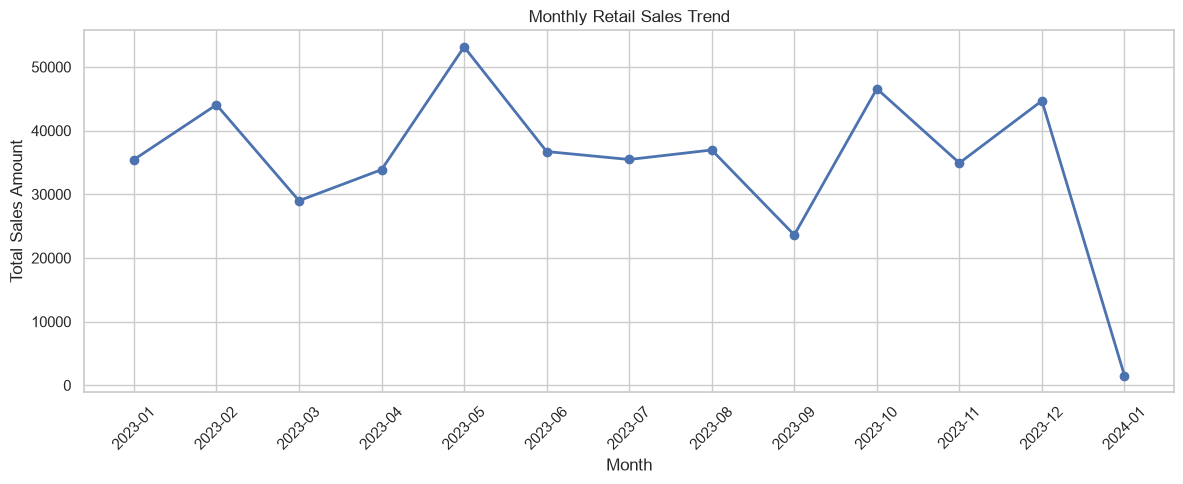

In [8]:
# Extract month and quarter from the transaction date
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculate monthly sales
monthly_sales = (
    df.groupby("Month")["Total Amount"]
    .sum()
    .sort_index()
)

# Plot monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.index = monthly_sales.index.astype(str)

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

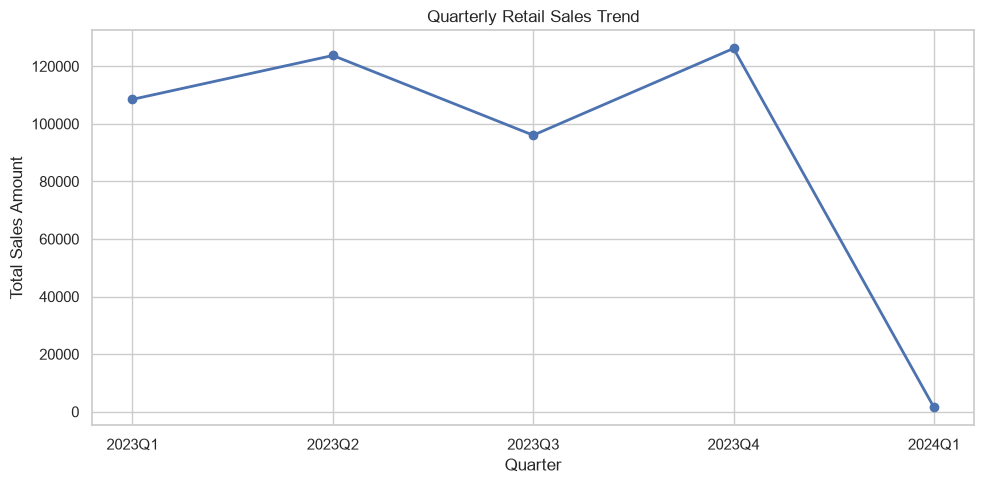

,Total Sales
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


In [9]:
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Amount")
plt.tight_layout()
plt.show()

display(quarterly_sales.rename("Total Sales").to_frame())

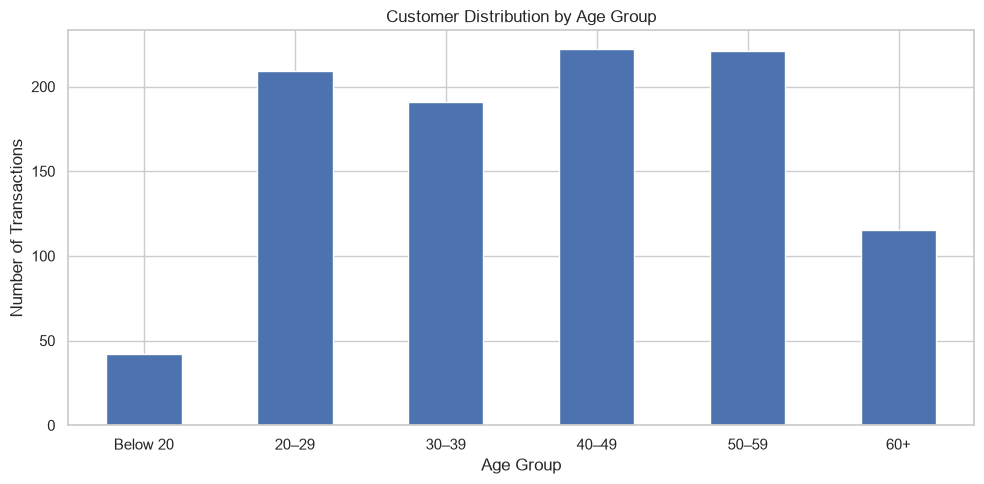

,Transaction Count
Age Group,
Below 20,42
20–29,209
30–39,191
40–49,222
50–59,221
60+,115


In [10]:
# Create age groups
age_bins = [0, 19, 29, 39, 49, 59, 100]
age_labels = [
    "Below 20", "20–29", "30–39",
    "40–49", "50–59", "60+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_distribution = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
age_distribution.plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_distribution.rename("Transaction Count").to_frame())

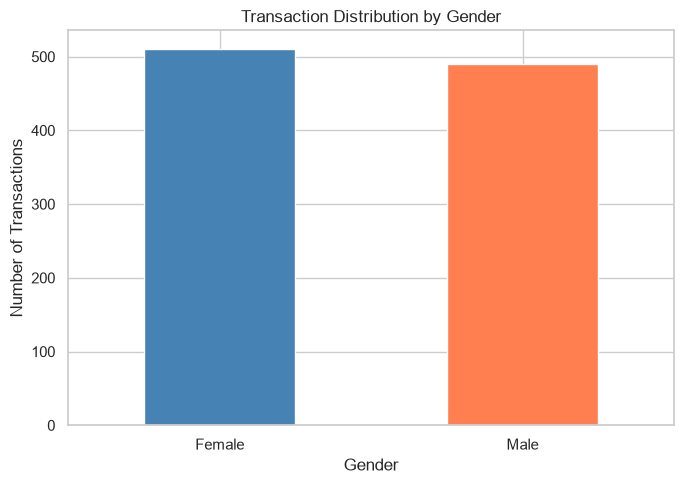

,Transaction Count
Gender,
Female,510
Male,490


In [11]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 5))
gender_counts.plot(
    kind="bar",
    color=["steelblue", "coral"]
)

plt.title("Transaction Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(gender_counts.rename("Transaction Count").to_frame())

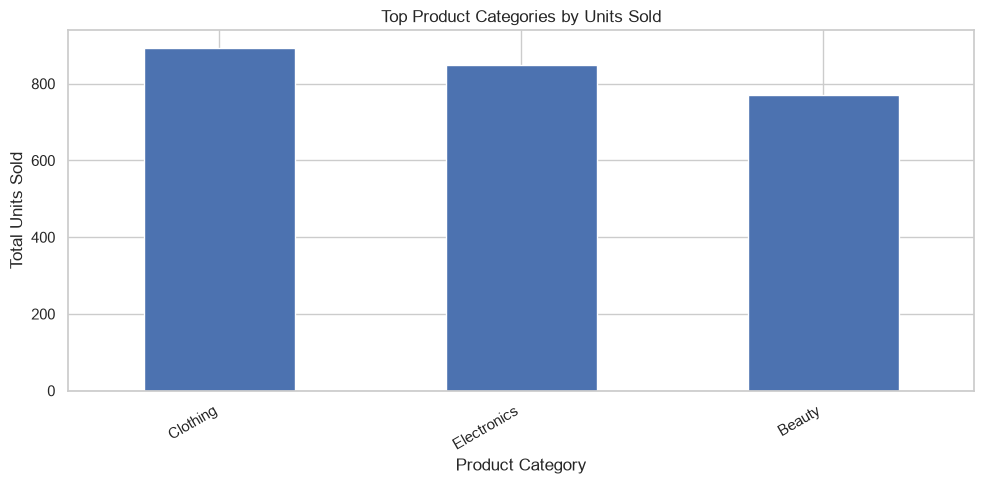

,Units Sold
Product Category,
Clothing,894
Electronics,849
Beauty,771


In [12]:
category_quantity = (
    df.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

top_categories = category_quantity.head(10)

plt.figure(figsize=(10, 5))
top_categories.plot(kind="bar")

plt.title("Top Product Categories by Units Sold")
plt.xlabel("Product Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(top_categories.rename("Units Sold").to_frame())

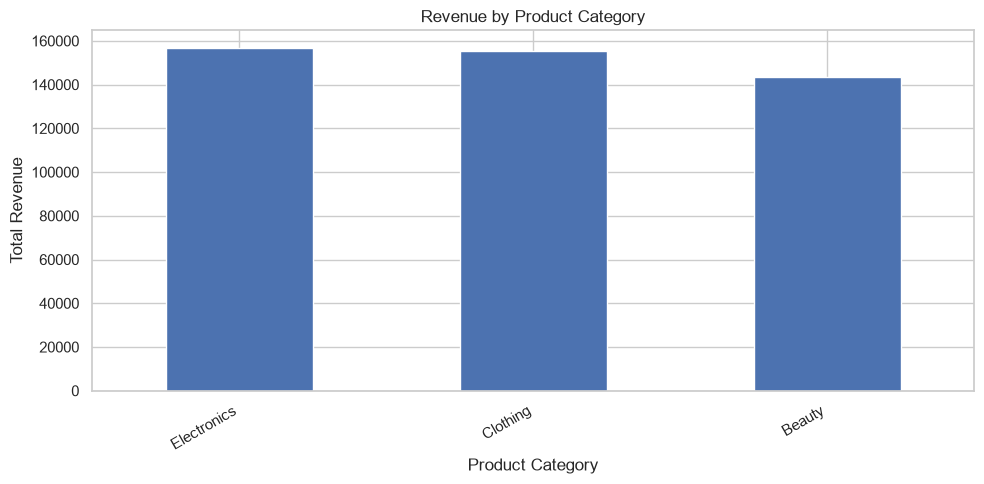

,Total Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [13]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(category_revenue.rename("Total Revenue").to_frame())

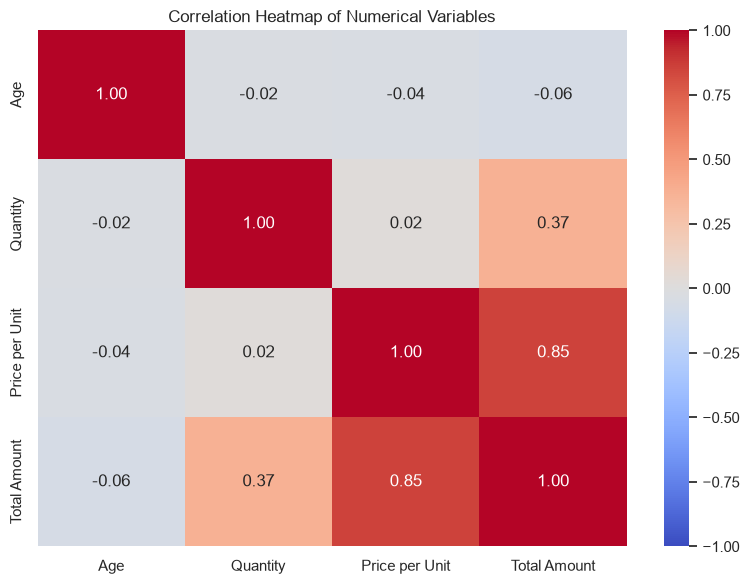

In [14]:
numerical_data = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

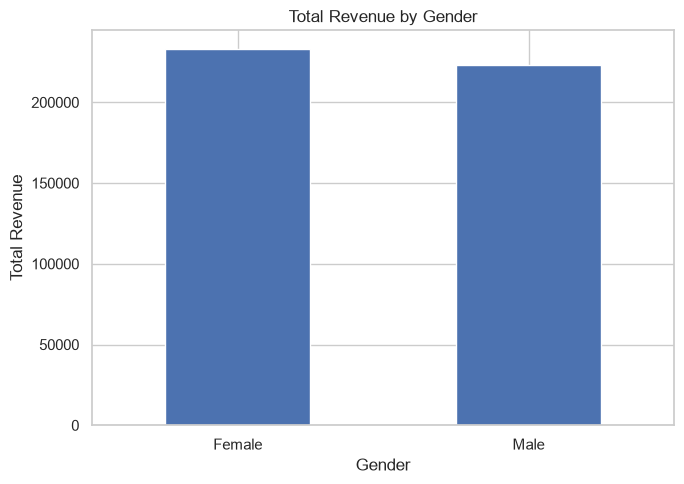

,Total Revenue
Gender,
Female,232840
Male,223160


In [15]:
gender_revenue = (
    df.groupby("Gender")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
gender_revenue.plot(kind="bar")

plt.title("Total Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(gender_revenue.rename("Total Revenue").to_frame())

In [16]:
average_transaction = (
    df.groupby("Gender")["Total Amount"]
    .mean()
    .round(2)
)

display(
    average_transaction
    .rename("Average Transaction Amount")
    .to_frame()
)

,Average Transaction Amount
Gender,
Female,456.55
Male,455.43
